# 1. Problem definition and data exploration

## Problem

**Task:** recognize the *predominant* instrument in an excerpt of real, polyphonic music. It is an 11-class classification problem over cello, clarinet, flute, acoustic guitar, electric guitar, organ, piano, saxophone, trumpet, violin and singing voice.

**Data:** the IRMAS dataset (Bosch et al., 2012).
- *Training data:* 6705 excerpts of 3 s, each labelled with one predominant instrument, taken from more than 2000 recordings.
- *Official test set:* 2874 excerpts of 5-20 s from other recordings, labelled with *all* predominant instruments (multi-label).

**Why it is hard:**
- The target instrument is mixed with accompaniment (drums, bass, other instruments).
- Recordings come from many decades, genres and production styles.
- The classes are imbalanced.
- Several excerpts come from the same recording, so a careless split leaks information.

**Approach:**
- Compute frame-level audio features in short windows: MFCCs, spectral centroid and zero-crossing rate. An extended set adds MFCC deltas, spectral contrast, rolloff, flatness and bandwidth (see "Choosing the features" below).
- Summarize them over the excerpt by temporal pooling (mean, or mean + standard deviation).
- Classify the pooled vector with four different kinds of model: Logistic Regression (linear), k-nearest neighbours (instance-based), an RBF SVM (kernel) and an MLP (neural network).

**Evaluation:**
- Accuracy and **macro F1**. Macro F1 weighs every instrument equally despite the class imbalance.
- Per-class precision and recall, and the confusion matrix.
- Micro/macro F1 on the official multi-label test set.

This notebook looks at the data. `02_training.ipynb` trains and saves the models, and `03_evaluation.ipynb` evaluates them.

In [1]:
import sys
from pathlib import Path

project_root = Path.cwd().parent
sys.path.append(str(project_root))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import soundfile as sf
import librosa
import librosa.display
from IPython.display import Audio, display
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

from src.config import DATA_DIR, TRAIN_DATA_DIR, CACHE_DIR, FIGURES_DIR, HOP_LENGTH, feature_spec, official_test_dirs
from src.data import download_irmas, load_dataset, load_test_dataset
from src.features import load_audio, frame_features_from_audio, build_pooled_features, assemble_features

FIGURES_DIR.mkdir(parents=True, exist_ok=True)

## Download the data

Downloads IRMAS from [Zenodo](https://zenodo.org/records/1290750) into `data/`, checks the MD5 checksums and extracts it. The dataset is free for non-commercial use (CC BY-NC-SA); see `data/README.txt`.

- **Sizes:** training data about 3.2 GB; the three test parts about 7.8 GB together (only needed for the official test set sections).
- **Disk space:** each archive is deleted after extraction, so the largest archive is the most that is ever stored twice. Plan for roughly 15 GB free.
- **Re-running:** parts that are already extracted are skipped, and an interrupted download resumes where it stopped.

In [2]:
DOWNLOAD_TEST_SET = True

download_irmas(DATA_DIR, include_test=DOWNLOAD_TEST_SET)

IRMAS-TrainingData: downloading
  IRMAS-TrainingData.zip: 3.15 / 3.18 GB
IRMAS-TrainingData: verifying checksum
IRMAS-TrainingData: extracting
IRMAS-TestingData-Part1: downloading
  IRMAS-TestingData-Part1.zip: 2.20 / 2.28 GB
IRMAS-TestingData-Part1: verifying checksum
IRMAS-TestingData-Part1: extracting
IRMAS-TestingData-Part2: downloading
  IRMAS-TestingData-Part2.zip: 3.36 / 3.39 GB
IRMAS-TestingData-Part2: verifying checksum
IRMAS-TestingData-Part2: extracting
IRMAS-TestingData-Part3: downloading
  IRMAS-TestingData-Part3.zip: 2.10 / 2.13 GB
IRMAS-TestingData-Part3: verifying checksum
IRMAS-TestingData-Part3: extracting
Done


## The training data

In [3]:
df = load_dataset(TRAIN_DATA_DIR)
df.head()

,filepath,label,label_short,recording_id,drums,genre
0,/home/user/Downloads/music-instrument-recognit...,cello,cel,0058,no_drums,classical
1,/home/user/Downloads/music-instrument-recognit...,cello,cel,0058,no_drums,classical
2,/home/user/Downloads/music-instrument-recognit...,cello,cel,0058,no_drums,classical
3,/home/user/Downloads/music-instrument-recognit...,cello,cel,0043,no_drums,classical
4,/home/user/Downloads/music-instrument-recognit...,cello,cel,0043,no_drums,classical


## Class distribution

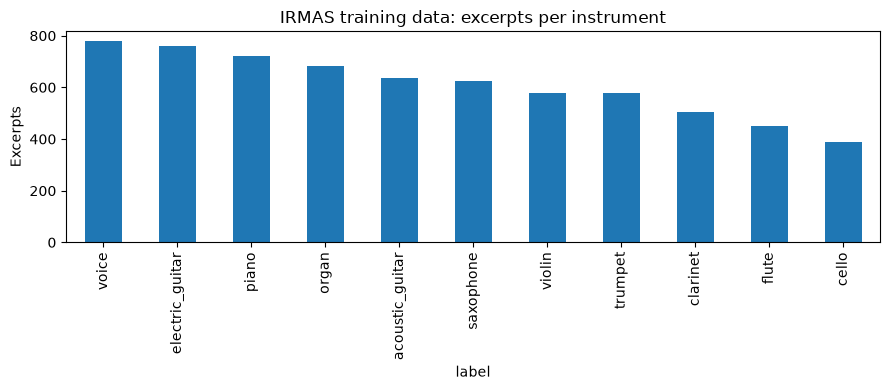

Total excerpts: 6705
Largest / smallest class: 2.01


In [4]:
class_counts = df["label"].value_counts()

fig, ax = plt.subplots(figsize=(9, 4))
class_counts.plot.bar(ax=ax)
ax.set_ylabel("Excerpts")
ax.set_title("IRMAS training data: excerpts per instrument")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "class_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

print("Total excerpts:", len(df))
print(f"Largest / smallest class: {class_counts.max() / class_counts.min():.2f}")

## Audio format

All training excerpts should be 3 s long, 44.1 kHz stereo. Features are computed on the mono downmix at the original sampling rate.

In [5]:
audio_info = pd.DataFrame([
    {"duration": info.duration, "samplerate": info.samplerate, "channels": info.channels}
    for info in map(sf.info, df["filepath"])
])

print(audio_info["samplerate"].value_counts().to_dict())
print(audio_info["channels"].value_counts().to_dict())
audio_info["duration"].describe()

{44100: 6705}
{2: 6705}


count    6.705000e+03
mean     2.999977e+00
std      4.441223e-16
min      2.999977e+00
25%      2.999977e+00
50%      2.999977e+00
75%      2.999977e+00
max      2.999977e+00
Name: duration, dtype: float64

## Recordings, genres and drums

The excerpts are not independent: several come from the same recording. The file names also contain the genre and whether drums are present. If the genres differ strongly between instruments (e.g. cello mostly classical), a model can partly learn genre or production style instead of the instrument.

In [6]:
excerpts_per_recording = df.groupby("recording_id").size()

print("Recordings:", df["recording_id"].nunique())
print("Excerpts per recording:", excerpts_per_recording.value_counts().sort_index().to_dict())
print("Recordings spanning more than one class:", (df.groupby("recording_id")["label"].nunique() > 1).sum())

Recordings: 2261
Excerpts per recording: {1: 11, 2: 86, 3: 2152, 4: 3, 6: 9}
Recordings spanning more than one class: 0


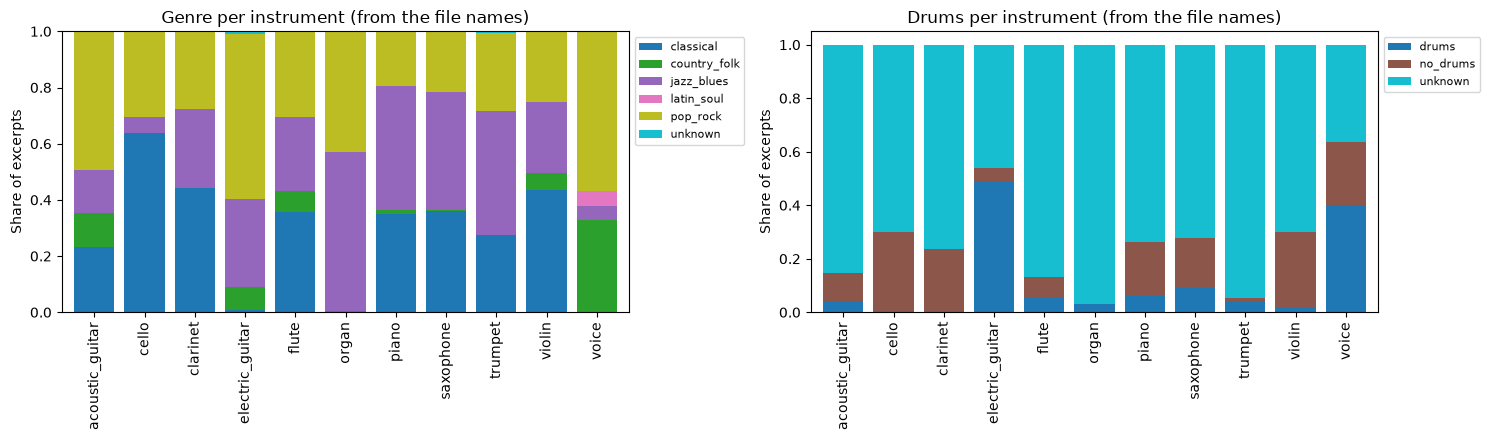

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))

for ax, column in zip(axes, ["genre", "drums"]):
    pd.crosstab(df["label"], df[column], normalize="index").plot.bar(stacked=True, ax=ax, colormap="tab10", width=0.8)
    ax.set_ylabel("Share of excerpts")
    ax.set_xlabel("")
    ax.set_title(f"{column.capitalize()} per instrument (from the file names)")
    ax.legend(bbox_to_anchor=(1.0, 1.0), loc="upper left", fontsize=8)

fig.tight_layout()
fig.savefig(FIGURES_DIR / "genre_drums_per_instrument.png", dpi=150, bbox_inches="tight")
plt.show()

## What the instruments look like

One example per instrument as a log-mel spectrogram. The spectral envelope (the distribution of energy over frequency) is what MFCCs summarize; the time structure (onsets, sustain, vibrato) is only partly kept by mean + std pooling.

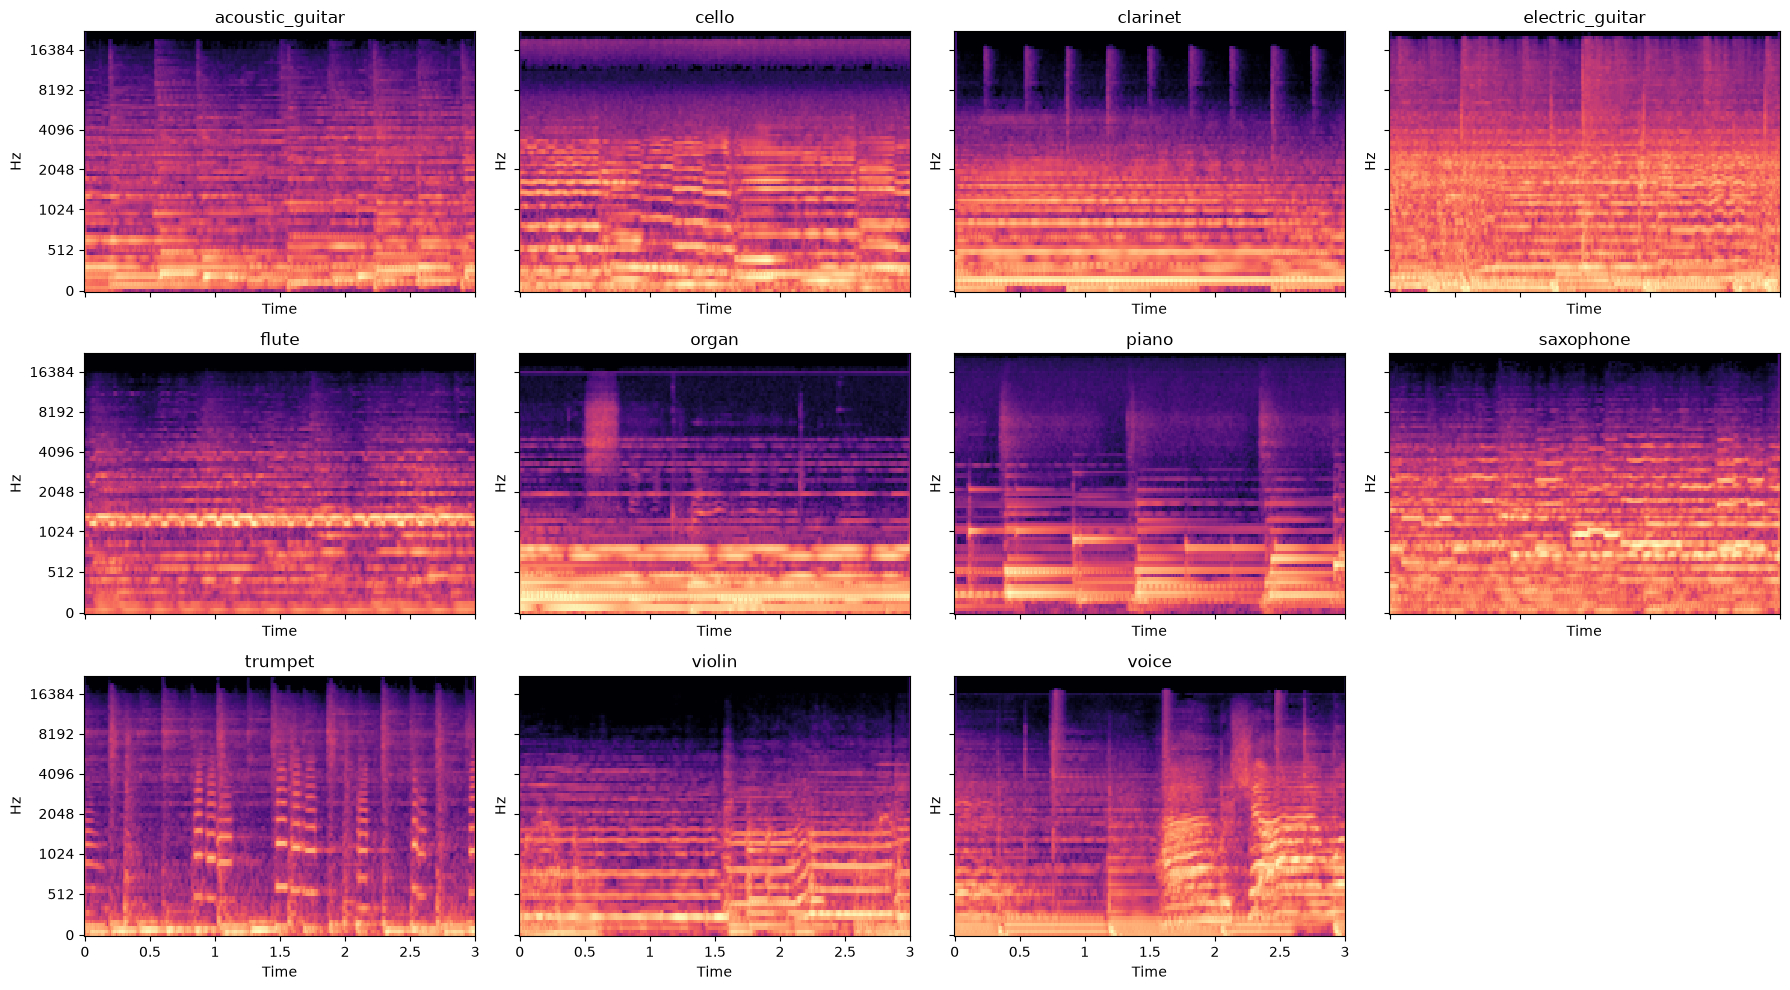

In [8]:
examples = df.groupby("label").sample(1, random_state=0).sort_values("label")

fig, axes = plt.subplots(3, 4, figsize=(18, 10), sharex=True, sharey=True)
for ax, (_, row) in zip(axes.flat, examples.iterrows()):
    y, sr = load_audio(row["filepath"])
    mel = librosa.power_to_db(librosa.feature.melspectrogram(y=y, sr=sr, n_mels=96), ref=np.max)
    librosa.display.specshow(mel, sr=sr, x_axis="time", y_axis="mel", ax=ax)
    ax.set_title(row["label"])
axes.flat[-1].axis("off")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "example_spectrograms.png", dpi=150, bbox_inches="tight")
plt.show()

In [9]:
for _, row in examples.iterrows():
    print(row["label"])
    y, sr = load_audio(row["filepath"])
    display(Audio(y, rate=sr))

acoustic_guitar


cello


clarinet


electric_guitar


flute


...

piano


saxophone


trumpet


violin


voice


## From audio to a feature vector

The procedure for one excerpt:
1. **Windowing:** the signal is cut into frames of 2048 samples (46 ms at 44.1 kHz) with a hop of 512 samples (11.6 ms).
2. **Frame features:** each frame gives e.g. 13 MFCCs, the spectral centroid and the zero-crossing rate (all features: see the next section).
3. **Temporal pooling:** each feature is summarized over all frames by its mean, or by mean and standard deviation.

The plot shows the frame features of one excerpt, with the pooled mean (line) and ± one standard deviation (band).

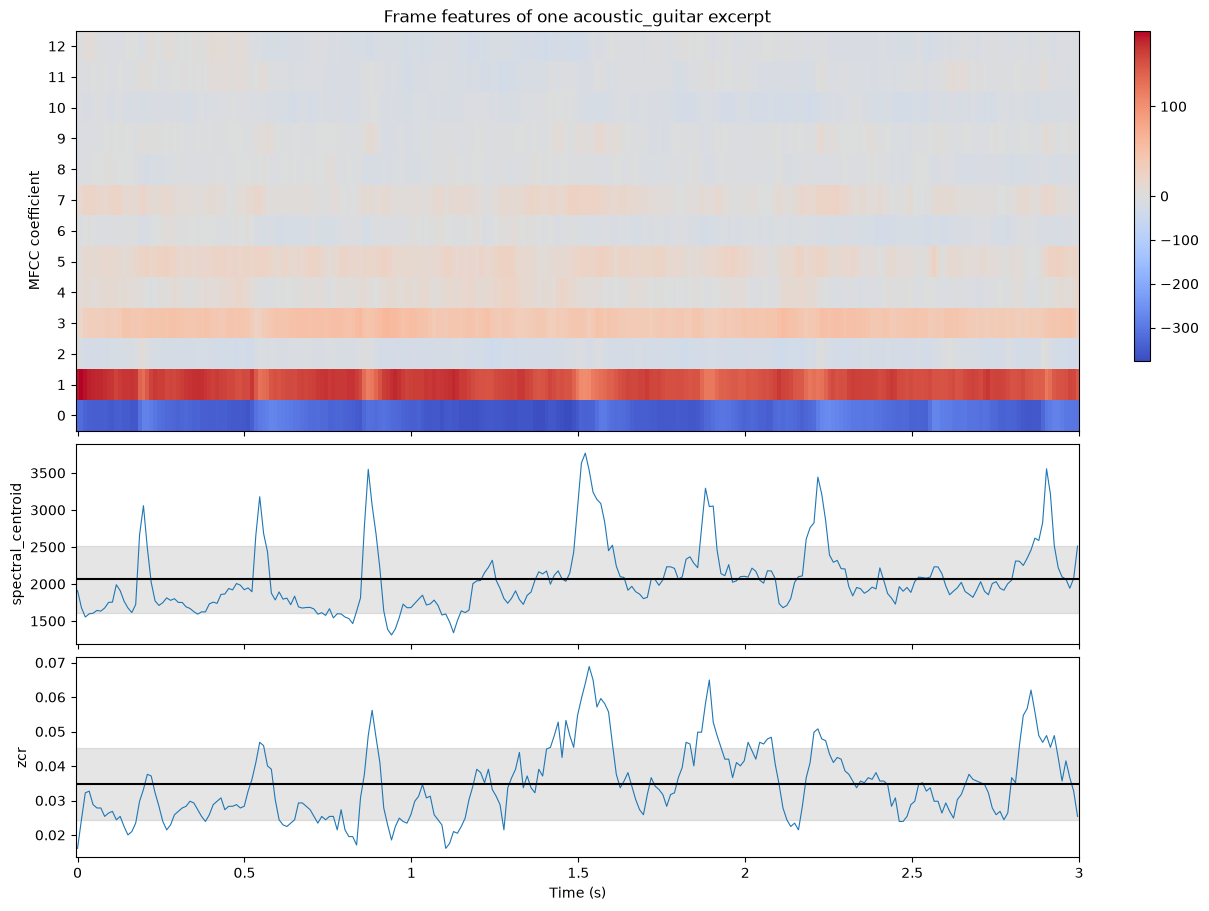

Frames: 259


In [10]:
example = examples.iloc[0]
y, sr = load_audio(example["filepath"])
frame_features = frame_features_from_audio(y, sr, n_mfcc=13)
times = librosa.times_like(frame_features["zcr"], sr=sr, hop_length=HOP_LENGTH)

fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True, gridspec_kw={"height_ratios": [2, 1, 1]}, layout="constrained")

image = librosa.display.specshow(frame_features["mfcc"], sr=sr, hop_length=HOP_LENGTH, x_axis="time", ax=axes[0])
n_mfcc = frame_features["mfcc"].shape[0]
axes[0].set_yticks(np.arange(n_mfcc), range(n_mfcc))
axes[0].set_ylabel("MFCC coefficient")
axes[0].set_xlabel("")
axes[0].set_title(f"Frame features of one {example['label']} excerpt")
fig.colorbar(image, ax=axes.tolist(), shrink=0.4, anchor=(0.0, 1.0))

for ax, name in zip(axes[1:], ["spectral_centroid", "zcr"]):
    values = frame_features[name][0]
    ax.plot(times, values, linewidth=0.8)
    ax.axhline(values.mean(), color="black")
    ax.axhspan(values.mean() - values.std(), values.mean() + values.std(), alpha=0.2, color="gray")
    ax.set_ylabel(name)
axes[-1].set_xlabel("Time (s)")

fig.savefig(FIGURES_DIR / "feature_extraction_example.png", dpi=150, bbox_inches="tight")
plt.show()

print("Frames:", frame_features["mfcc"].shape[1])

## Choosing the features

Instrument recognition is about **timbre**: what makes a violin and a flute playing the same note at the same loudness sound different. Timbre shows up in the spectral envelope (which harmonics are strong), in how noisy vs. tonal the sound is, and in how the sound evolves over time (attack, decay, vibrato). The features are chosen to cover these aspects:

| Feature | What it describes | Why it helps here |
|---|---|---|
| **MFCCs** | Smoothed spectral envelope on a perceptual (mel) frequency scale, decorrelated by a DCT | The standard timbre descriptor: formant-like resonances of the instrument body (e.g. clarinet's weak even harmonics, the voice's formants) |
| **Delta MFCCs** | Frame-to-frame change of the MFCCs | Pooled MFCCs lose time. Their deltas (and the std of the deltas) keep how fast the envelope changes: percussive attack and decay (piano, guitar) vs. sustained tones (organ, wind, bowed strings), and vibrato |
| **Spectral contrast** | Peak-to-valley energy ratio in 6 octave bands + 1 | Separates clear harmonic peaks (flute, clarinet) from dense or noisy spectra (distorted guitar, organ registers, breathy voice), and works per band, which is more robust in a mix than one global number |
| **Spectral centroid** | Centre of mass of the spectrum | Brightness: trumpet and violin are bright, cello and clarinet low register darker |
| **Spectral rolloff** | Frequency below which 85% of the energy lies | Upper extent of the spectrum, complements the centroid |
| **Spectral bandwidth** | Spread of the spectrum around the centroid | Narrow (pure, few harmonics: flute) vs. wide (rich: brass, distorted guitar) |
| **Spectral flatness** | How noise-like (flat) vs. tone-like (peaky) the spectrum is | Breath and bow noise, cymbals in the mix vs. clean tones |
| **Zero-crossing rate** | Sign changes per sample | Cheap time-domain cue for noisiness and brightness |

**Not used: chroma / pitch features.** Chroma describes *which notes* are played (pitch classes), and it is designed to be invariant to timbre. Every instrument here can play every pitch class, so chroma carries information about the music (key, harmony), not about the instrument, and would mostly add noise. The pitch *range* of an instrument could help a little, but in polyphonic mixes it is unreliable to estimate.

**Parameters to verify, not assume.** The first experiments used the library defaults. `02_training.ipynb` tests the choices that matter most for this application on the validation split:
- **Number of MFCCs (13 / 20 / 40).** More coefficients keep finer spectral detail. That detail can help separate similar timbres but also starts to describe pitch (individual harmonics).
- **MFCC 0 (kept / dropped).** Coefficient 0 is the overall log energy, i.e. loudness. It depends on the recording level, not the instrument.
- **Window length (1024 / 2048 / 4096 samples = 23 / 46 / 93 ms, hop fixed at 512).** Longer windows resolve harmonics better, especially for low instruments such as cello; shorter windows capture attacks better.
- **Contribution of each feature group.** Each group is removed in turn to check that it is needed.

## Feature distributions per instrument

The pooled features of all excerpts are extracted here (2048-sample window) and cached in `cache/features/`, where the training notebook reuses them.

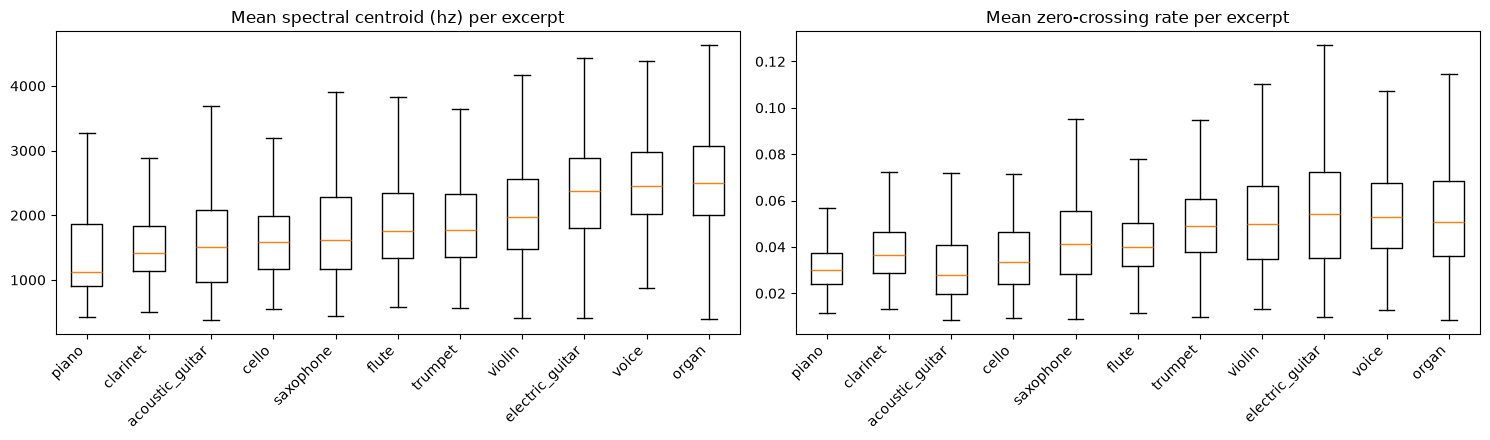

In [11]:
pooled = build_pooled_features(df, n_fft=2048, hop_length=HOP_LENGTH, cache_path=CACHE_DIR / "train_nfft2048.npz")

low_level = pd.DataFrame({
    "Spectral centroid (Hz)": pooled["spectral_centroid_mean"][:, 0],
    "Zero-crossing rate": pooled["zcr_mean"][:, 0]
})
low_level["label"] = df["label"].values
order = low_level.groupby("label")["Spectral centroid (Hz)"].median().sort_values().index

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for ax, column in zip(axes, ["Spectral centroid (Hz)", "Zero-crossing rate"]):
    ax.boxplot([low_level.loc[low_level["label"] == label, column] for label in order], showfliers=False)
    ax.set_xticks(range(1, len(order) + 1), order, rotation=45, ha="right")
    ax.set_title(f"Mean {column.lower()} per excerpt")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "low_level_features_per_instrument.png", dpi=150, bbox_inches="tight")
plt.show()

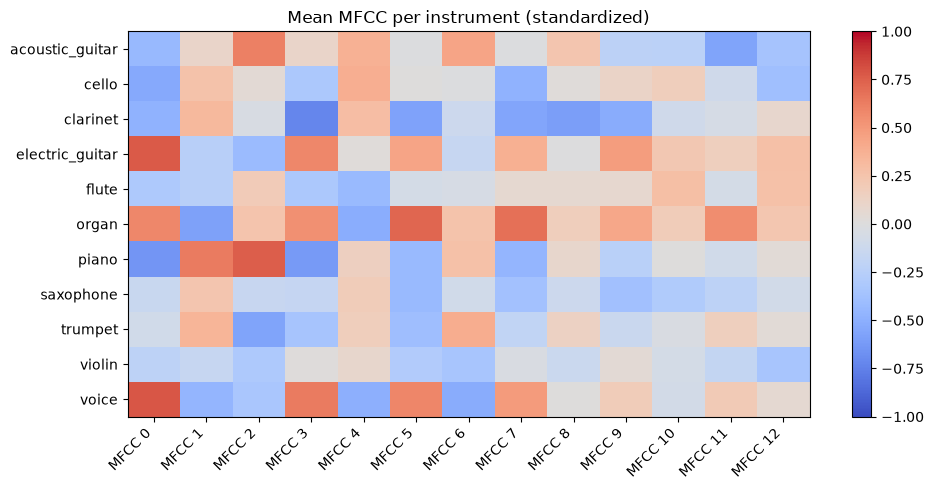

In [12]:
# Average MFCC profile per instrument (each coefficient standardized over all excerpts)
mfcc_means = pd.DataFrame(StandardScaler().fit_transform(pooled["mfcc_mean"][:, :13]))
mfcc_profile = mfcc_means.groupby(df["label"].values).mean()

fig, ax = plt.subplots(figsize=(10, 5))
image = ax.imshow(mfcc_profile, cmap="coolwarm", vmin=-1, vmax=1, aspect="auto")
ax.set_xticks(range(mfcc_profile.shape[1]), [f"MFCC {i}" for i in range(mfcc_profile.shape[1])], rotation=45, ha="right")
ax.set_yticks(range(len(mfcc_profile)), mfcc_profile.index)
ax.set_title("Mean MFCC per instrument (standardized)")
fig.colorbar(image, ax=ax)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "mfcc_profile_per_instrument.png", dpi=150, bbox_inches="tight")
plt.show()

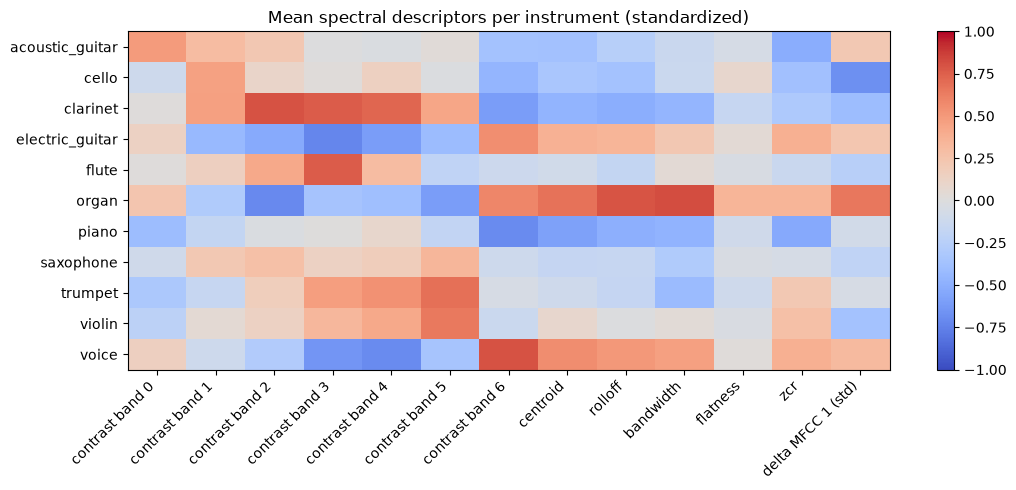

In [13]:
# Average profile of the other descriptors per instrument (mean over frames; standardized over all excerpts)
descriptor_columns = {f"contrast band {i}": pooled["spectral_contrast_mean"][:, i] for i in range(pooled["spectral_contrast_mean"].shape[1])}
for name in ["spectral_centroid", "spectral_rolloff", "spectral_bandwidth", "spectral_flatness", "zcr"]:
    descriptor_columns[name.replace("spectral_", "")] = pooled[f"{name}_mean"][:, 0]
descriptor_columns["delta MFCC 1 (std)"] = pooled["delta_mfcc_std"][:, 1]

descriptors = pd.DataFrame(StandardScaler().fit_transform(pd.DataFrame(descriptor_columns)), columns=list(descriptor_columns))
descriptor_profile = descriptors.groupby(df["label"].values).mean()

fig, ax = plt.subplots(figsize=(11, 5))
image = ax.imshow(descriptor_profile, cmap="coolwarm", vmin=-1, vmax=1, aspect="auto")
ax.set_xticks(range(descriptor_profile.shape[1]), descriptor_profile.columns, rotation=45, ha="right")
ax.set_yticks(range(len(descriptor_profile)), descriptor_profile.index)
ax.set_title("Mean spectral descriptors per instrument (standardized)")
fig.colorbar(image, ax=ax)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "descriptor_profile_per_instrument.png", dpi=150, bbox_inches="tight")
plt.show()

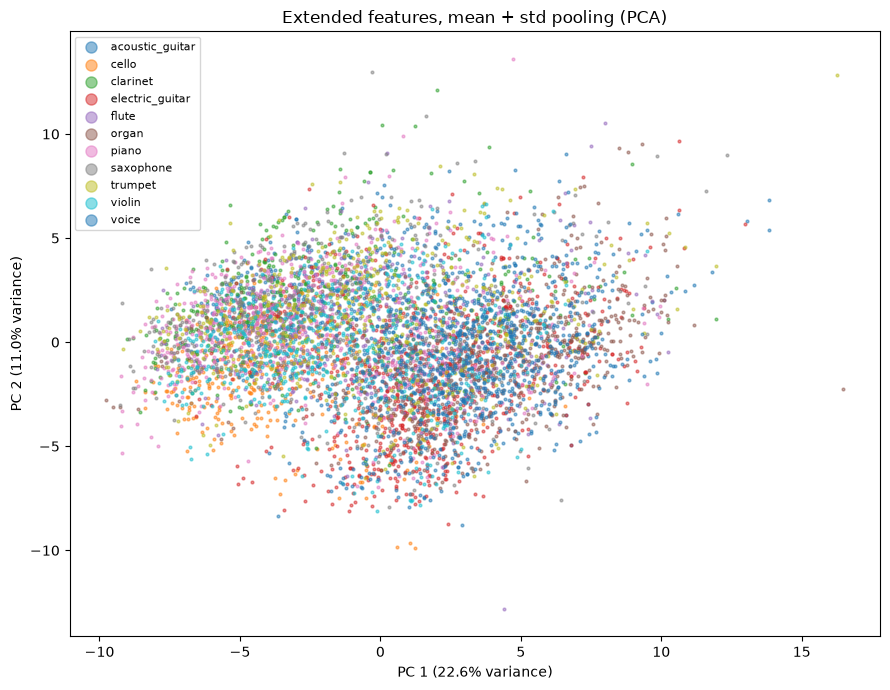

In [14]:
# 2D PCA of the extended mean + std features: how separable are the classes?
x_scaled = StandardScaler().fit_transform(assemble_features(pooled, feature_spec("extended"), "mean_std"))
pca = PCA(n_components=2, random_state=0)
x_2d = pca.fit_transform(x_scaled)

fig, ax = plt.subplots(figsize=(9, 7))
for label in sorted(df["label"].unique()):
    mask = df["label"].values == label
    ax.scatter(x_2d[mask, 0], x_2d[mask, 1], s=4, alpha=0.5, label=label)
ax.set_xlabel(f"PC 1 ({pca.explained_variance_ratio_[0]:.1%} variance)")
ax.set_ylabel(f"PC 2 ({pca.explained_variance_ratio_[1]:.1%} variance)")
ax.set_title("Extended features, mean + std pooling (PCA)")
ax.legend(markerscale=4, fontsize=8)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "pca_extended_mean_std.png", dpi=150, bbox_inches="tight")
plt.show()

## Official test set

Excerpts: 2874


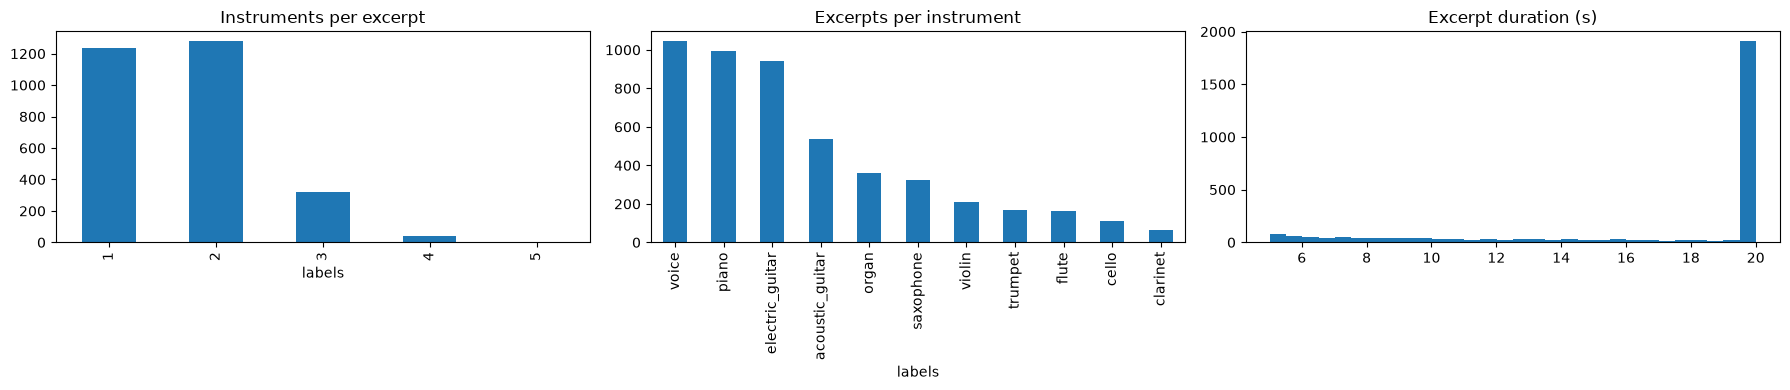

In [15]:
official_df = load_test_dataset(official_test_dirs())
print("Excerpts:", len(official_df))

if len(official_df):
    official_df["duration"] = [sf.info(filepath).duration for filepath in official_df["filepath"]]

    fig, axes = plt.subplots(1, 3, figsize=(18, 4))
    official_df["labels"].str.len().value_counts().sort_index().plot.bar(ax=axes[0], title="Instruments per excerpt")
    official_df["labels"].explode().value_counts().plot.bar(ax=axes[1], title="Excerpts per instrument")
    axes[2].hist(official_df["duration"], bins=30)
    axes[2].set_title("Excerpt duration (s)")
    fig.tight_layout()
    fig.savefig(FIGURES_DIR / "official_test_set.png", dpi=150, bbox_inches="tight")
    plt.show()

## Observations

*To be filled in after running:*
- class imbalance (largest / smallest class) and why it motivates macro F1;
- genre/drums differences between instruments (possible shortcuts for the model);
- which instruments separate already by spectral centroid / ZCR, and which overlap;
- which descriptors differ most between instruments in the profile heatmaps;
- how much the classes overlap in the PCA plot (does a linear model have a chance?);
- how the official test set differs from the training data (length, several instruments).